In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

In [2]:
plt.style.use('default')
warnings.filterwarnings('ignore', category=FutureWarning)

In [3]:
# Load the dataset house
df = pd.read_csv("Bengaluru_House_Data.csv")
df.head()

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  str    
 1   availability  13320 non-null  str    
 2   location      13319 non-null  str    
 3   size          13304 non-null  str    
 4   society       7818 non-null   str    
 5   total_sqft    13320 non-null  str    
 6   bath          13247 non-null  float64
 7   balcony       12711 non-null  float64
 8   price         13320 non-null  float64
dtypes: float64(3), str(6)
memory usage: 936.7 KB


In [5]:
df.describe()

,bath,balcony,price
count,13247.000000,12711.000000,13320.000000
mean,2.692610,1.584376,112.565627
std,1.341458,0.817263,148.971674
min,1.000000,0.000000,8.000000
25%,2.000000,1.000000,50.000000
50%,2.000000,2.000000,72.000000
75%,3.000000,2.000000,120.000000
max,40.000000,3.000000,3600.000000


In [6]:
df.shape

(13320, 9)

In [7]:
df.dtypes

area_type           str
availability        str
location            str
size                str
society             str
total_sqft          str
bath            float64
balcony         float64
price           float64
dtype: object

In [8]:
#Missing values analysis. See if we can add values to the columns that are missed or drop them
Missing = pd.DataFrame({"missing count": df.isnull().sum(), "missing_%":df.isnull().mean() * 100}).sort_values("missing_%", ascending=False)
Missing

,missing count,missing_%
society,5502,41.306306
balcony,609,4.572072
bath,73,0.548048
size,16,0.120120
location,1,0.007508
area_type,0,0.000000
availability,0,0.000000
total_sqft,0,0.000000
price,0,0.000000


In [9]:
#Now we handle missing values, after analysis how many missing values? We first drop the columns which has the highest number of missing values, the rest we fill it with the median.
df = df.drop(columns=["society"], errors="ignore")
df["bath"] = df["bath"].fillna(df["bath"].median())
df["balcony"] = df["balcony"].fillna(df["balcony"].median())
df = df.dropna()


In [10]:
df.columns

Index(['area_type', 'availability', 'location', 'size', 'total_sqft', 'bath',
       'balcony', 'price'],
      dtype='str')

In [11]:
df.describe()

,bath,balcony,price
count,13303.000000,13303.000000,13303.000000
mean,2.689619,1.602872,112.584033
std,1.339393,0.803455,148.993820
min,1.000000,0.000000,8.000000
25%,2.000000,1.000000,50.000000
50%,2.000000,2.000000,72.000000
75%,3.000000,2.000000,120.000000
max,40.000000,3.000000,3600.000000


In [12]:
# We check if we still have null values after that
df.isnull().sum()

area_type       0
availability    0
location        0
size            0
total_sqft      0
bath            0
balcony         0
price           0
dtype: int64

In [13]:
# we display all the values in total_sqft
df["total_sqft"].value_counts().unique()

array([843, 221, 204, 195, 180, 172, 132, 123, 117, 114, 112, 108, 104,
       101, 100,  91,  82,  70,  69,  67,  66,  63,  62,  60,  59,  58,
        57,  56,  55,  53,  52,  48,  46,  45,  44,  43,  42,  41,  40,
        39,  38,  37,  36,  35,  34,  33,  32,  31,  30,  29,  28,  27,
        25,  24,  23,  22,  21,  20,  19,  18,  17,  16,  15,  14,  13,
        12,  11,  10,   9,   8,   7,   6,   5,   4,   3,   2,   1])

In [14]:
df.info()
# By using this function we will see that total_sqft column is categorised as object/category while we don't have any category in the colum values as we saw but int/numeric values. So we need to change it into int column

<class 'pandas.DataFrame'>
Index: 13303 entries, 0 to 13319
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13303 non-null  str    
 1   availability  13303 non-null  str    
 2   location      13303 non-null  str    
 3   size          13303 non-null  str    
 4   total_sqft    13303 non-null  str    
 5   bath          13303 non-null  float64
 6   balcony       13303 non-null  float64
 7   price         13303 non-null  float64
dtypes: float64(3), str(5)
memory usage: 935.4 KB


In [15]:
# Change total_sqft column from category/object data type into int
# We create a function first
def convert_sqft(x):
    try:
        if '-' in x:
            a,b = x.split('-')
            return(float(a) + float(b)) / 2
        return float(x)
    except:
        return np.nan

In [16]:
# Now we call the function to be used in total_sqft column
df["total_sqft"] = df["total_sqft"].astype(str).apply(convert_sqft)
df = df.dropna(subset=["total_sqft"])
df.info()

<class 'pandas.DataFrame'>
Index: 13257 entries, 0 to 13319
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13257 non-null  str    
 1   availability  13257 non-null  str    
 2   location      13257 non-null  str    
 3   size          13257 non-null  str    
 4   total_sqft    13257 non-null  float64
 5   bath          13257 non-null  float64
 6   balcony       13257 non-null  float64
 7   price         13257 non-null  float64
dtypes: float64(4), str(4)
memory usage: 932.1 KB


In [17]:
df["total_sqft"].value_counts().unique()

array([843, 221, 204, 195, 180, 173, 132, 123, 117, 114, 112, 108, 104,
       101, 100,  91,  82,  71,  69,  67,  66,  63,  60,  59,  58,  56,
        55,  53,  52,  48,  46,  45,  44,  43,  42,  41,  40,  39,  38,
        37,  36,  35,  34,  33,  32,  31,  30,  29,  28,  27,  26,  25,
        24,  23,  22,  21,  20,  19,  18,  17,  16,  15,  14,  13,  12,
        11,  10,   9,   8,   7,   6,   5,   4,   3,   2,   1])

In [18]:
# Now we extract BHK and make it a column and delete size
df["BHK"] = df["size"].apply(lambda x: int(x.split()[0]))
df = df.drop(columns=["size"])


In [19]:
df["BHK"].isnull().sum()


np.int64(0)

In [20]:
df.info()

<class 'pandas.DataFrame'>
Index: 13257 entries, 0 to 13319
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13257 non-null  str    
 1   availability  13257 non-null  str    
 2   location      13257 non-null  str    
 3   total_sqft    13257 non-null  float64
 4   bath          13257 non-null  float64
 5   balcony       13257 non-null  float64
 6   price         13257 non-null  float64
 7   BHK           13257 non-null  int64  
dtypes: float64(4), int64(1), str(3)
memory usage: 932.1 KB


In [21]:
# We have total_sqft but we don't have price per total_sqft. So we need to calculate that bcoz it is going to be used whenever we'll try to perform price distribution or in our data visualization. Now we'll create one more column called price per sqft
df["price_per_sqft"] = (df["price"]*100000) / df["total_sqft"]

In [22]:
df.info()

<class 'pandas.DataFrame'>
Index: 13257 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   area_type       13257 non-null  str    
 1   availability    13257 non-null  str    
 2   location        13257 non-null  str    
 3   total_sqft      13257 non-null  float64
 4   bath            13257 non-null  float64
 5   balcony         13257 non-null  float64
 6   price           13257 non-null  float64
 7   BHK             13257 non-null  int64  
 8   price_per_sqft  13257 non-null  float64
dtypes: float64(5), int64(1), str(3)
memory usage: 1.0 MB


In [23]:
df.shape


(13257, 9)

In [24]:
# Clean location text by removing extra spaces
df["location"] = df["location"].str.strip()

We are removing the outliers. We remove the data/records that are wrong in the table we have or which are extreme.

In [25]:
# We save rows now so that at the end we can report how many rows the cleaning removed.
rows_before = len(df)

In [26]:
# Keep only rows that are at least ~300 sqft per bedroom
df = df[df["total_sqft"] / df["BHK"] >= 300]

In [27]:
# Keep rows where bath is at most BHK + 2(bathrooms not far above bedrooms) and remove the rest.
df = df[df["bath"] <= df["BHK"] + 2]

In [28]:
# drop the most extreme price-per-sqft values (bottom and top 1%). The lowest 1% and the highest 1%. About 98% of rows survive this step.
low, high = df["price_per_sqft"].quantile([0.01, 0.99])
df = df[df["price_per_sqft"].between(low, high)]
print(f" Rows before: {rows_before}, rows after {len(df)} (removed {rows_before - len(df)})")

 Rows before: 13257, rows after 12252 (removed 1005)


In [29]:
df["price_per_sqft"].max()

np.float64(21250.0)

In [30]:
df["price_per_sqft"].isnull().sum()

np.int64(0)

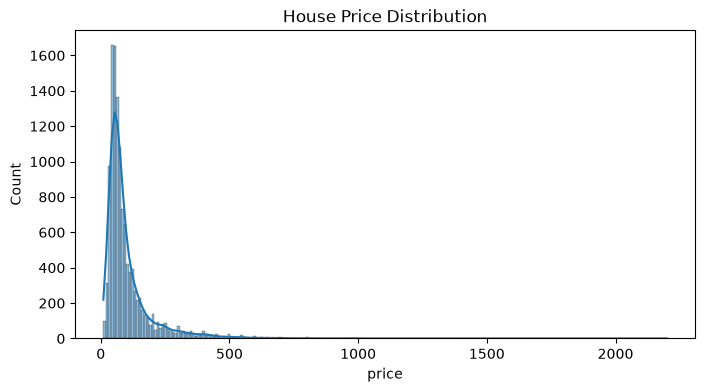

In [31]:
# Now we let's see the price distribution that show how the price is distributed among all the flights. And we'll see the count versus price
# Price distribution based on the counts
plt.figure(figsize=(8,4))
sns.histplot(df["price"], kde = True)
plt.title("House Price Distribution")
plt.show()

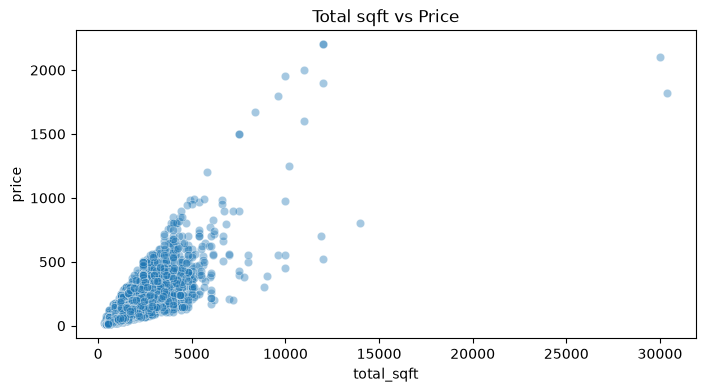

In [32]:
# We analyze between total_sqft versus the price
plt.figure(figsize = (8,4))
sns.scatterplot(x="total_sqft", y="price", data=df, alpha = 0.4)
plt.title("Total sqft vs Price")
plt.show()

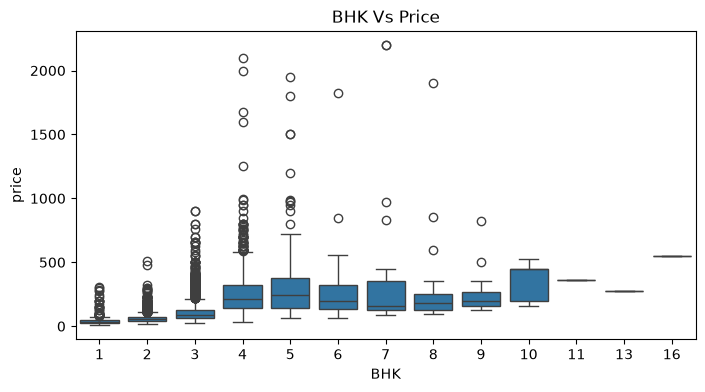

In [33]:
# We analyze the "BHK" versus the price. But we have not yet removed the outliers
plt.figure(figsize = (8, 4))
sns.boxplot(x="BHK", y="price", data=df)
plt.title("BHK Vs Price")
plt.show()

In [34]:
# We include location. We can have a location with price per square foot. The top 10 locations by the average price per sqft
loc_stats = df.groupby("location")["price_per_sqft"].agg(["median", "count"])
top = loc_stats[loc_stats["count"] >= 15].sort_values("median", ascending=False).head(10)

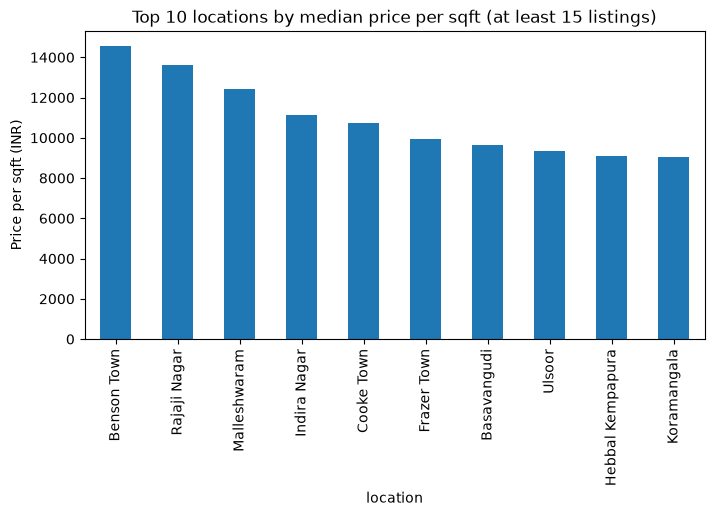

In [35]:
top["median"].plot(kind="bar", figsize=(8, 4))
plt.title("Top 10 locations by median price per sqft (at least 15 listings)")
plt.xlabel("location")
plt.ylabel("Price per sqft (INR)")
plt.tight_layout
plt.show()

In [36]:
df.info()

<class 'pandas.DataFrame'>
Index: 12252 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   area_type       12252 non-null  str    
 1   availability    12252 non-null  str    
 2   location        12252 non-null  str    
 3   total_sqft      12252 non-null  float64
 4   bath            12252 non-null  float64
 5   balcony         12252 non-null  float64
 6   price           12252 non-null  float64
 7   BHK             12252 non-null  int64  
 8   price_per_sqft  12252 non-null  float64
dtypes: float64(5), int64(1), str(3)
memory usage: 957.2 KB


In [37]:
# Since we still have some columns with object/category as datatype value, we'll have to extract/change/convert them to numeric Dtype
# Convert availabilty into binary form 1 or 0
def availability_to_binary(x):
    if pd.isna(x):
        return np.nan
    x = str(x).lower()
    if x in ["ready to move", "immediate"]:
        return 1
    else:
        return 0

In [38]:
df["availability"] = df["availability"].astype(str).apply(availability_to_binary)

In [39]:
df["availability"].value_counts()

availability
1    9623
0    2629
Name: count, dtype: int64

In [40]:
df.info()

<class 'pandas.DataFrame'>
Index: 12252 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   area_type       12252 non-null  str    
 1   availability    12252 non-null  int64  
 2   location        12252 non-null  str    
 3   total_sqft      12252 non-null  float64
 4   bath            12252 non-null  float64
 5   balcony         12252 non-null  float64
 6   price           12252 non-null  float64
 7   BHK             12252 non-null  int64  
 8   price_per_sqft  12252 non-null  float64
dtypes: float64(5), int64(2), str(2)
memory usage: 957.2 KB


In [41]:
df.head()

,area_type,availability,location,total_sqft,bath,balcony,price,BHK,price_per_sqft
0,Super built-up Area,0,Electronic City Phase II,1056.0,2.0,1.0,39.07,2,3699.810606
1,Plot Area,1,Chikka Tirupathi,2600.0,5.0,3.0,120.00,4,4615.384615
2,Built-up Area,1,Uttarahalli,1440.0,2.0,3.0,62.00,3,4305.555556
3,Super built-up Area,1,Lingadheeranahalli,1521.0,3.0,1.0,95.00,3,6245.890861
4,Super built-up Area,1,Kothanur,1200.0,2.0,1.0,51.00,2,4250.000000


In [42]:
df.groupby("location")["price_per_sqft"].idxmax().sort_values(ascending=False)

location
Annaiah Reddy Layout                               13302
Abshot Layout                                      13262
Havanur extension                                  13261
12th cross srinivas nagar banshankari 3rd stage    13245
Nagappa Reddy Layout                               13209
                                                   ...  
Cholanayakanahalli                                    77
Tharabanahalli                                        60
Adarsh Nagar                                          50
KR Puram                                              48
Thanisandra                                           22
Name: price_per_sqft, Length: 1180, dtype: int64

In [43]:
print(df["price_per_sqft"].describe())

count    12252.000000
mean      6096.625228
std       2952.154292
min       2549.743590
25%       4237.918216
50%       5294.117647
75%       6863.035155
max      21250.000000
Name: price_per_sqft, dtype: float64


In [44]:
df.sort_values("price_per_sqft", ascending=False).head(10)

,area_type,availability,location,total_sqft,bath,balcony,price,BHK,price_per_sqft
4992,Plot Area,1,Banashankari Stage II,2400.0,3.0,2.0,510.0,5,21250.000000
4855,Built-up Area,1,R.T. Nagar,800.0,1.0,0.0,170.0,2,21250.000000
5946,Plot Area,1,Wilson Garden,4000.0,6.0,3.0,850.0,6,21250.000000
5403,Plot Area,1,4th T block Jayanagar,2080.0,4.0,2.0,440.0,4,21153.846154
11493,Built-up Area,1,1st Phase JP Nagar,1900.0,3.0,1.0,400.0,4,21052.631579
11831,Plot Area,1,Banashankari,2400.0,4.0,3.0,500.0,4,20833.333333
3867,Plot Area,1,4th Block Koramangala,2400.0,4.0,2.0,500.0,4,20833.333333
12639,Plot Area,1,1st Stage Indira Nagar,2400.0,4.0,1.0,500.0,4,20833.333333
5639,Plot Area,1,Kasturi Nagar,1200.0,4.0,2.0,250.0,4,20833.333333
9805,Plot Area,1,Hennur Road,2400.0,5.0,3.0,500.0,4,20833.333333


In [45]:
df[df["location"] == "Grihalakshmi Layout"]

,area_type,availability,location,total_sqft,bath,balcony,price,BHK,price_per_sqft


In [46]:
print(top)

                        median  count
location                             
Benson Town       14573.991031     15
Rajaji Nagar      13598.780488     96
Malleshwaram      12415.349887     47
Indira Nagar      11145.598872     38
Cooke Town        10755.295429     16
Frazer Town        9927.219796     35
Basavangudi        9629.629630     29
Ulsoor             9330.882353     16
Hebbal Kempapura   9117.647059     33
Koramangala        9062.043796     70


## Conclusion

I have done an analysis of house prices using the Bengaluru House Price
dataset from Kaggle.

**Data and cleaning**
- The dataset had 13,320 listings and 9 columns. Prices are in lakhs of rupees.
- `society` was missing in 41% of rows, so I dropped the column. Missing `bath`
  (73) and `balcony` (609) values were filled with the median.
- I removed 17 rows with a missing `size` or `location`, and 46 rows whose
  `total_sqft` could not be converted to a number (units such as Sq. Meter
  or Perch).
- I removed 1,005 more rows (7.6%) as outliers: fewer than 300 sqft per
  bedroom, more than BHK + 2 bathrooms, and the lowest and highest 1% of
  price per sqft.
- In total, 1,068 rows (8%) were removed, leaving 12,252.
- Before removing outliers, the highest price per sqft was 1,200,000, which is
  clearly an error. Afterwards the maximum is 21,250 and the median is 5,294.
- `availability` was turned into a yes/no column: 9,623 listings (about 79%)
  are ready to move.

**What the data shows**
- Prices are right-skewed: the median price is [median] lakh but the mean is
  [mean] lakh, because a few expensive listings pull the average up.
- Half of the listings cost between about 4,200 and 6,900 rupees per sqft.
- The most expensive areas by median price per sqft (areas with at least 15
  listings) are Benson Town ([value]), Rajaji Nagar ([value]), Malleshwaram
  ([value]), Indira Nagar and Cooke Town.
- Price rises clearly with size. It also rises with the number of bedrooms up
  to about 4 to 5 BHK, then stops rising. The larger categories have few
  listings, so their medians are less reliable.

**Limitations**
- Prices are asking prices, not final sale prices.
- Removing the top 1% of price per sqft caps the data at 21,250, so the most
  luxurious listings are excluded and expensive areas may be understated.
- My cleaning rules (300 sqft per bedroom, BHK + 2, 1% cut-offs) are judgment
  calls. Different thresholds would remove different rows.
- Some locations are spelled in more than one way and were not merged.
- This analysis shows relationships between variables, not causes.

**Next steps**
- Build a regression model to predict price from size, BHK, bathrooms,
  location and area type, and evaluate it with R² and MAE.